# Multivariate Normalverteilung

[Vortragsaufzeichnung zur multivariaten Normalverteilung](https://media.hhu.de/channel/video/data-science-vl-13-multivariate-normalverteilung-2025/caa8a4203ac6ef5db3cd928ecad06918/167)

## Dichten von multivariaten Verteilungen

Wir erinnern uns: Bei einer Dichtefunktion $f \colon \mathbb{R} \to [0,\infty)$ für eine Verteilung $P$ einer reellen Zufallsvariable $X$ ist $P(X < c) = \int_{-\infty}^c f(x)dx$.

Wenn wir das auf zwei Dimensionen verallgemeinern wollen, also eine Zufallsvariable $(X,Y)$ mit Werten in $\mathbb{R}^2$, dann ist $P(X < c, Y < d) = \int_{-\infty}^c \int_{-\infty}^d f(x,y)dx dy$.

Daran sehen wir: die Dichtefunktion muss die Signatur $f \colon \mathbb{R}^2 \to [0,\infty)$ haben. Sie kodiert für jeden möglichen Wert von $(X,Y)$ die Wahrscheinlichkeitsdichte.

Allgemeiner definiert eine Funktion $f \colon \mathbb{R}^n \to [0,\infty)$ mit $\int_{\mathbb{R}^n} f(x)dx = 1$ ein Wahrscheinlichkeitsmaß $P$ mit $P(A) = \int_A f(x)dx$ und man nennt $f$ eine Dichte für die Verteilung $P$.

## Die Multivariate Normalverteilung

:::{admonition} Definition
Sei $n \in \mathbb{N}$, $\mu \in \mathbb{R}^n$ und $\Sigma \in Mat(n \times n; \mathbb{R})$ eine positiv definite symmetrische Matrix.

Dann heißt die Verteilung zur Dichtefunktion


$$
\phi(x) = \dfrac{1}{\sqrt{(2\pi)^{n}\det(\Sigma)}} exp\left( -\dfrac{ (x-\mu)^T \Sigma^{-1}(x-\mu) }{ 2 } \right)
$$

*n-dimensionale (multivariate) Normalverteilung mit Erwartungswert $\mu$ und Kovarianzmatrix $\Sigma$*.
:::

Diese Verteilung hat in der Tat den Erwartungswert und die Kovarianzmatrix wie im Namen und man schreibt auch $\mathcal{N}(\mu,\Sigma)$.

In [1]:
import numpy as np
import scipy.stats as st
import matplotlib.pyplot as plt

In [2]:
# Bivariate Normalverteilung instantiieren:
def getmvn_by_rho(rho=0.7):
    origin = [0, 0]
    Sigma = np.array([[1,   rho],
                      [rho,   1]])
    Z = st.multivariate_normal(mean=origin, cov=Sigma)
    return Sigma, Z

In [3]:
# Stichprobe ziehen:
def samplexy(Sigma, Z, size=1000000):
    sample = Z.rvs(size=size)
    x, y = sample[:,0], sample[:,1]
    # Stichprobenkovarianz == Sigma
    assert np.all(np.isclose(Sigma,
                             np.round(np.cov(x,y),
                                      decimals=2)))
    return x, y

Tipp: Lesen Sie nach, wie in Numpy *meshgrids* (und damit verbunden die Funktion mgrid) funktionieren. Hinweis: es ist eine Art explizites vorab-Broadcasting, damit dann arithmetische Operationen schneller vektorisiert laufen (probieren Sie es mit kleinen meshgrids selbst aus, eine Funktion in zwei Variablen, Z.B. $x^2+y^2$, auf einem meshgrid vektorisiert auszuwerten).

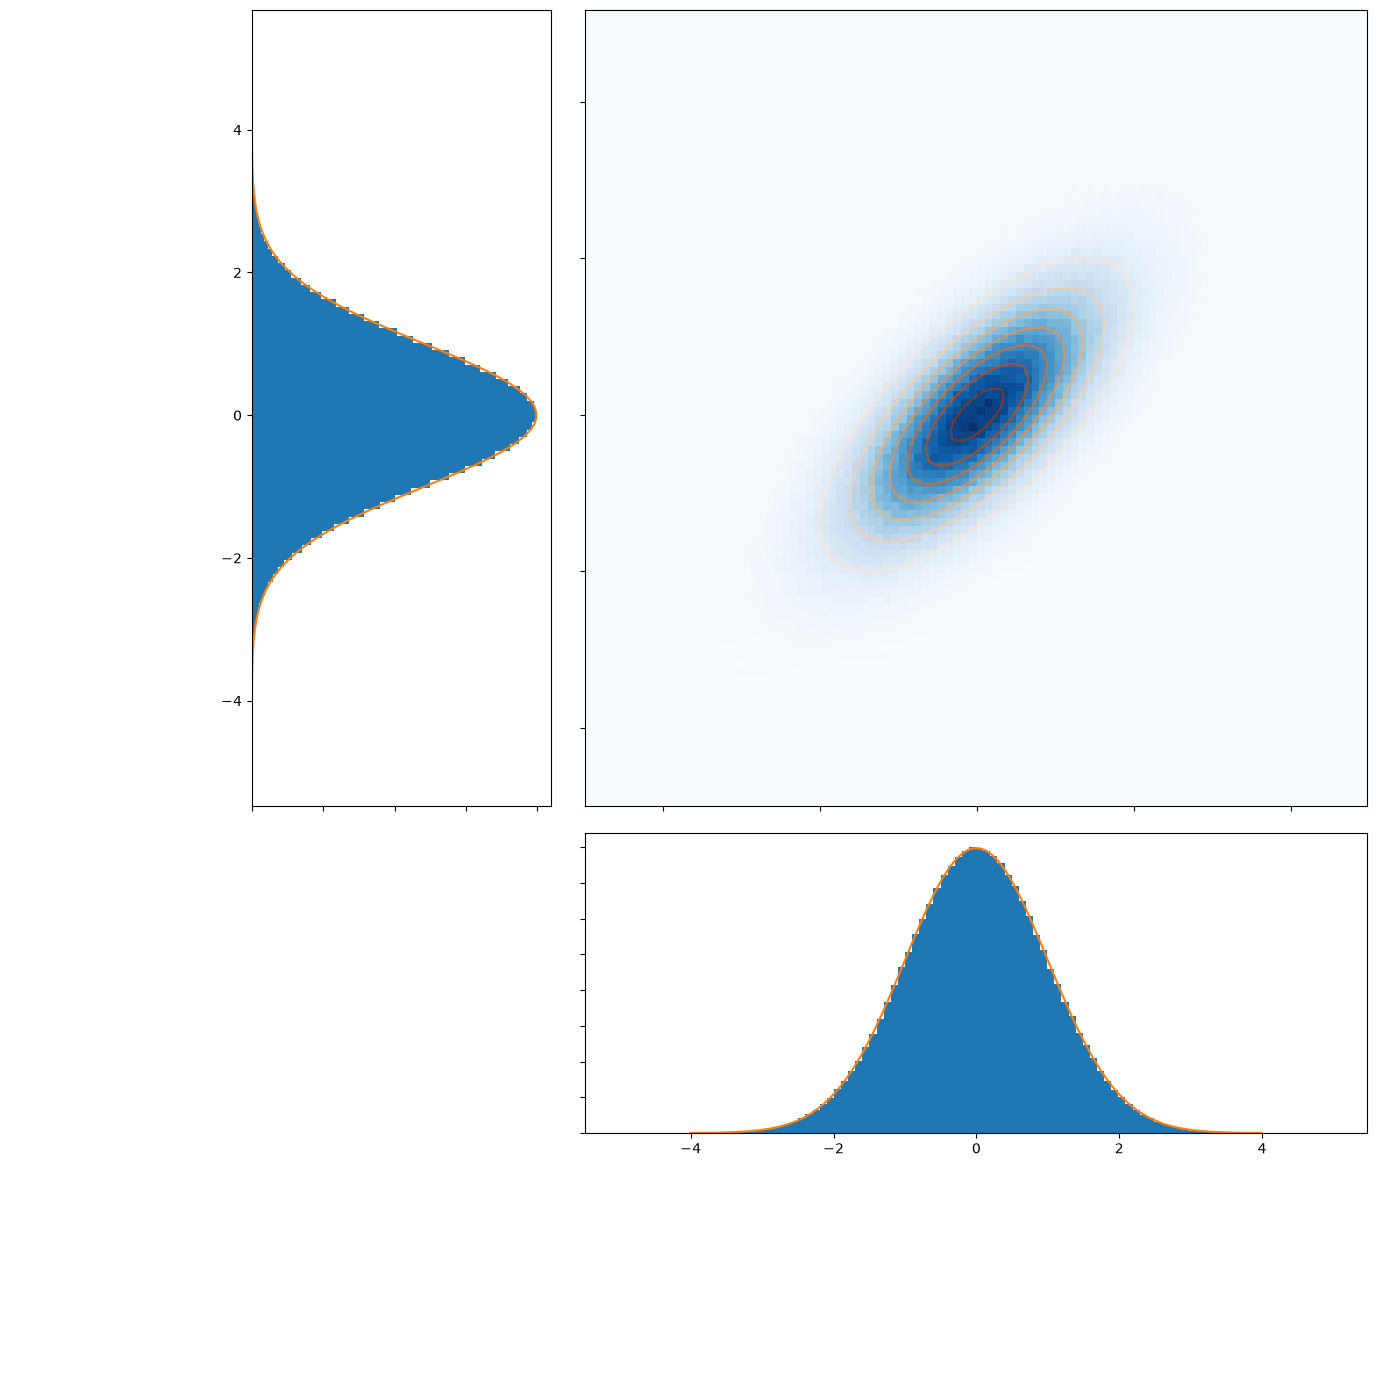

In [4]:
# 2D Plotten:
def plotalot(x, y, Z):
    fig, axs = plt.subplots(2,2, figsize=(9,9))
    fig.tight_layout(pad=-18)   # negatives Padding: die Randhistogramme sollen direkt am Hauptplot anliegen
    axs[0,1].hist2d(x, y, bins=100, cmap=plt.cm.Blues)
    xs, ys = np.mgrid[-5:5:.1, -5:5:.1] # meshgrid
    axs[0,1].contour(xs, ys,
                     Z.pdf(np.dstack((xs, ys))),
                     cmap=plt.cm.Oranges, alpha=.7)
    axs[0,1].set_xticklabels([])
    axs[0,1].set_yticklabels([])
    axs[1,1].hist(x, bins=100, density=True)
    axs[1,1].plot(xl := np.linspace(-4,4,100),
                  st.norm.pdf(xl, loc=0, scale=1))
    axs[1,1].set_yticklabels([])
    axs[1,1].set_aspect(10)
    axs[0,0].hist(y, bins=100, density=True,
                  orientation="horizontal")
    axs[0,0].plot(st.norm.pdf(yl := np.linspace(-4,4,100), loc=0, scale=1),
                  yl)
    axs[0,0].set_xticklabels([])
    axs[0,0].set_aspect(0.1)
    axs[1,0].set_axis_off()
    plt.show()

def plot_by_rho(rho=0.7):
    Sigma, Z = getmvn_by_rho(rho)
    x, y = samplexy(Sigma, Z)
    plotalot(x, y, Z)
    
plot_by_rho()

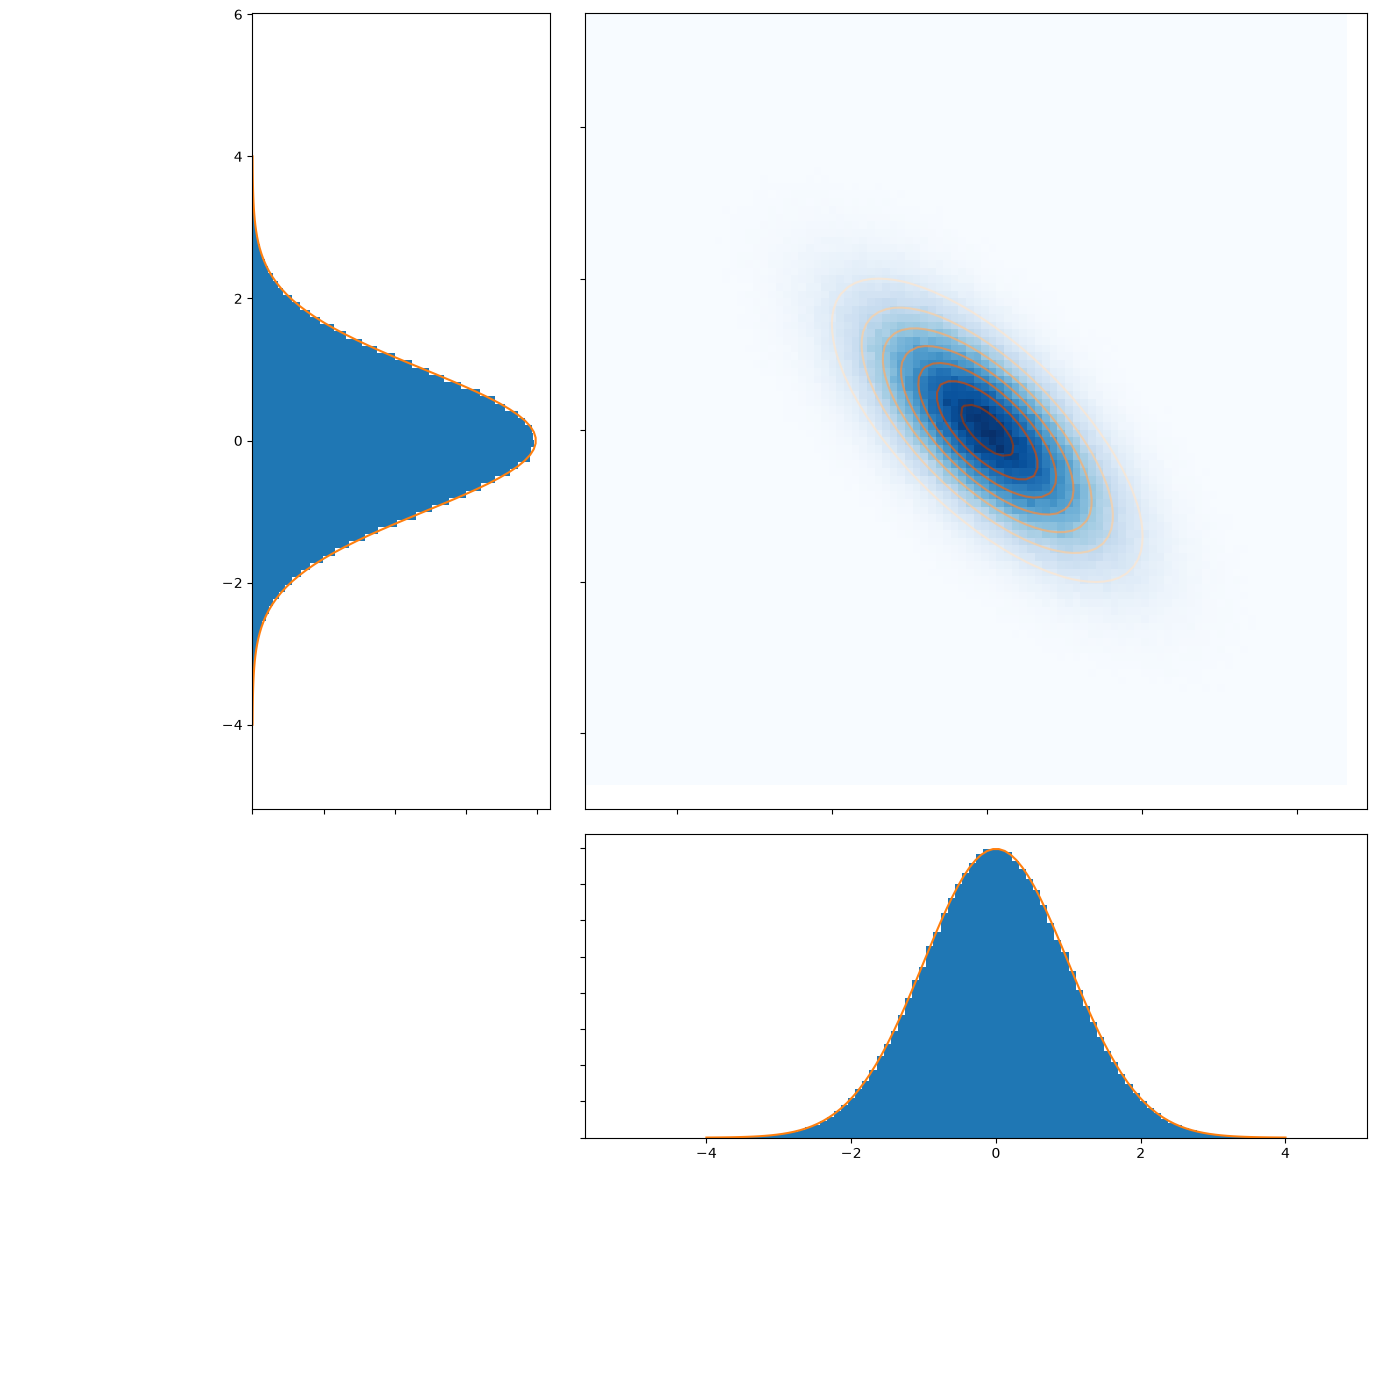

In [5]:
# negativ korreliert sieht es so aus:
plot_by_rho(-0.7)

Wir sehen also, die Marginalverteilungen sehen exakt gleich aus - man kann die Korrelation nur in der gemeinsamen Verteilung sehen (da aber deutlich im zweidimensionalen Histogramm (wird auch Heatmap genannt) und im Konturplot (den Ellipsen)).

Die Kovarianzmatrix hat eine direkte geometrische Interpretation, denn jede positiv definite symmetrische Matrix $A$ definiert ein Skalarprodukt $\langle v, w \rangle_A := \langle Av, w\rangle = (Av)^Tw = v^TA^Tw = v^TAw = \langle v, Aw\rangle$ und damit eine sogenannte quadratische Form $v \mapsto \langle v, v \rangle_A$. Die Konturlinien (Levelsets) der quadratischen Form sind Ellipsen entlang der gleichen Achsen wie die Konturlinien der entsprechenden Normalverteilung.

In der Formel, die die Dichte der multivariaten Normalverteilung definiert, taucht für den Vektor $v = x - \mu$ die Formel $v^T \Sigma^{-1} v$ auf, das ist genau das Skalarprodukt, welches durch die Matrix $\Sigma^{-1}$ definiert wird. Die Dichte ist also $c \cdot e^{-Q(v)/2}$ mit $Q(v) := v^T \Sigma^{-1} v$ und einer Konstanten $c$, und die Levelsets der Dichte sind genau die Levelsets von $Q$. Für $\Sigma = \begin{pmatrix} 1 & \rho \\ \rho & 1 \end{pmatrix}$ ist $\Sigma^{-1} = \frac{1}{1-\rho^2}\begin{pmatrix} 1 & -\rho \\ -\rho & 1 \end{pmatrix}$.

:::{admonition} Bemerkung
**Die multivariate Normalverteilung ist immer unimodal.** Weil $\Sigma^{-1}$ positiv definit ist, gilt $Q(v) \geq 0$ mit Gleichheit nur für $v = 0$, und entlang jedes Strahls von $\mu$ weg wächst $Q$ streng monoton. Die Dichte $c \cdot e^{-Q(v)/2}$ hat also genau ein Maximum, nämlich bei $x = \mu$, und fällt in jede Richtung davon ab — unabhängig davon, wie $\Sigma$ aussieht, also auch bei negativer Kovarianz oder sehr unterschiedlichen Varianzen. Die Kovarianzmatrix verformt den Gipfel zu einer Ellipse, sie kann keinen zweiten erzeugen. Sieht ein zweidimensionales Histogramm zwei Gipfel, ist das deshalb ein sicheres Zeichen, dass die Daten *nicht* aus einer einzigen Normalverteilung stammen — sondern etwa aus einer Mischung mehrerer, wie im Kapitel [Expectation-Maximization](expectation-maximization.ipynb).
:::

Man kann die Kovarianzmatrix als Drehstreckung interpretieren - sie kodiert genau, wie die Ellipse aus einem perfekten Kreis hervorgeht. Der Kreis entspricht der Identität (Einheitsmatrix) als Kovarianzmatrix. Wenn $\Sigma$ in die eine Richtung dreht, dreht $\Sigma^{-1}$ genau in die Gegenrichtung.

Sie können sich ja vorstellen, was aus dem gewöhnlichen Skalarprodukt wird, wenn man einen der beiden Vektoren vor dem Einsetzen einer Drehstreckung unterwirft.

Um die Geometrie besser verstehen zu können, empfiehlt es sich mit bivariaten Normalverteilungen anzufangen, und dabei die Matrix $\Sigma$ langsam komplizierter zu machen (Vielfache einer Einheitsmatrix, Diagonalmatrizen mit verschiedenen Einträgen auf der Diagonalen, beliebige Matrizen). Eine beliebige Kovarianzmatrix $\Sigma$ kann stets durch einen orthogonalen Basiswechsel in Diagonalgestalt gebracht werden, d.h. durch eine Drehung des Raums lässt sich die Ellipse (die Konturlinie der Normalverteilung) achsenparallel machen. Durch Skalierung der Achsen lässt sich die Ellipse in einen Kreis verwandeln. So gesehen ist jede Normalverteilung eine Standardnormalverteilung, nur in anderen Koordinaten.


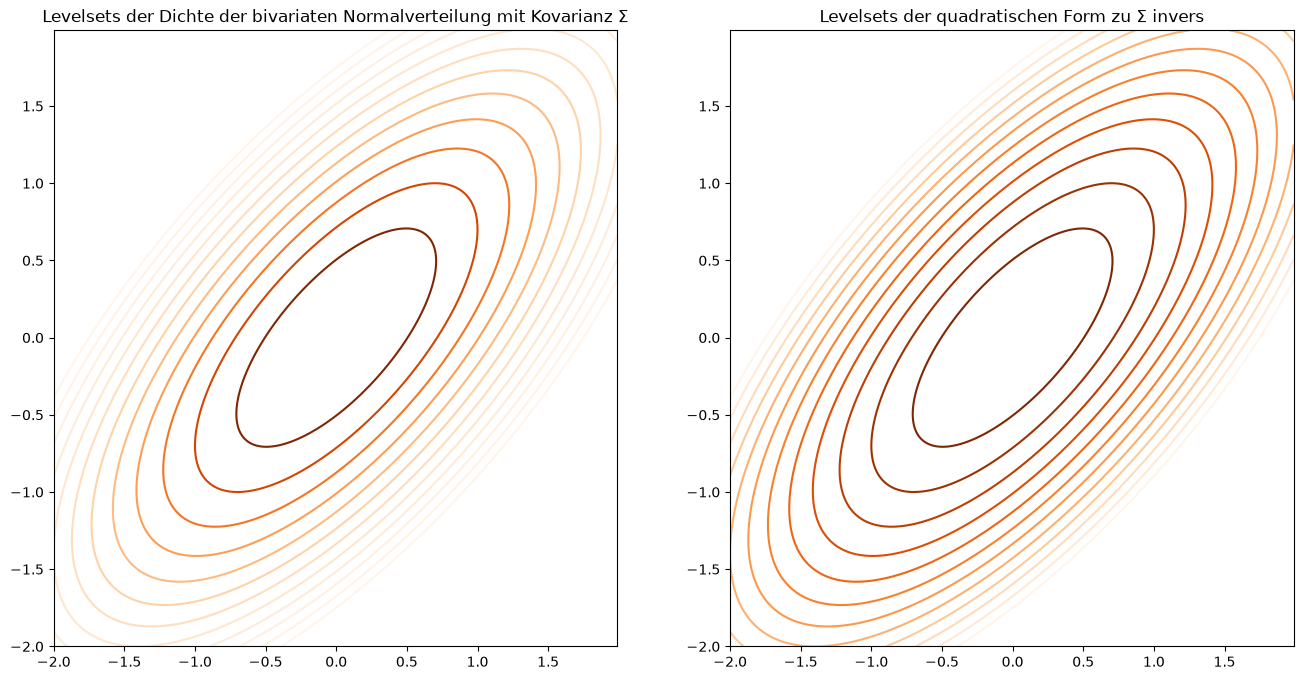

In [6]:
rho = 0.7
Sigma, Z = getmvn_by_rho(rho)
Sigma_inv = np.linalg.inv(Sigma)   # = 1/(1-rho^2) * [[1, -rho], [-rho, 1]]

def Q(x, y):
    """Quadratische Form v^T Σ^{-1} v für v = (x, y)"""
    return Sigma_inv[0,0]*x**2 + 2*Sigma_inv[0,1]*x*y + Sigma_inv[1,1]*y**2

xs, ys = np.mgrid[-2:2:.01, -2:2:.01]

# Die Dichte ist c * exp(-Q/2) mit c = 1/(2 pi sqrt(det Σ)). Wir zeichnen links und rechts
# dieselben Niveaus, damit man sieht, dass es dieselben Ellipsen sind:
levels_Q = np.arange(0.5, 6.5, 0.5)
c = 1 / (2 * np.pi * np.sqrt(np.linalg.det(Sigma)))
levels_pdf = np.sort(c * np.exp(-levels_Q / 2))

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(16,8))
ax1.contour(xs, ys,
            Z.pdf(np.dstack((xs, ys))),
            levels=levels_pdf,
            cmap=plt.cm.Oranges)
ax1.set_title("Levelsets der Dichte der bivariaten Normalverteilung mit Kovarianz Σ")
ax2.contour(xs, ys, Q(xs, ys),
            levels=levels_Q,
            cmap=plt.cm.Oranges_r)
ax2.set_title("Levelsets der quadratischen Form zu Σ invers")

plt.show()

Die Achsen der Ellipsen kann man auch ausrechnen: Sie sind die Eigenvektoren von $\Sigma$, und die Wurzeln der Eigenwerte geben (bis auf einen gemeinsamen Faktor) die Längen der Halbachsen an. Für $\Sigma = \begin{pmatrix} 1 & \rho \\ \rho & 1 \end{pmatrix}$ sind das die beiden Diagonalen mit den Eigenwerten $1+\rho$ und $1-\rho$. Das Kapitel zur [Dimensionsreduktion](dimensionsreduktion.ipynb) baut genau auf dieser Eigenzerlegung auf:

In [7]:
werte, vektoren = np.linalg.eigh(Sigma)   # Sigma ist symmetrisch, daher eigh (Eigenwerte aufsteigend)
print("Eigenwerte:", werte)               # 1 - rho und 1 + rho
print("Eigenvektoren (Spalten):")
print(vektoren)                           # (1,-1)/√2 und (1,1)/√2: die Achsen der Ellipsen

Eigenwerte: [0.3 1.7]
Eigenvektoren (Spalten):
[[-0.70710678  0.70710678]
 [ 0.70710678  0.70710678]]


Damit wir auch das dreidimensionale Plotten mit matplotlib kennen lernen, schauen wir nochmal auf die Dichtefunktion der Normalverteilung:

In [8]:
# 3D Plotten:
from mpl_toolkits.mplot3d import axes3d

rho = 0.5
Sigma, Z = getmvn_by_rho(rho)

def plot3dangles(a, b, fig, where):
    ax = fig.add_subplot(where, projection='3d')
    ax.view_init(a, b)
    ax.set_zticklabels([])
    ax.plot_surface(xs, ys, Z.pdf(np.dstack((xs, ys))),
                    rstride=5, cstride=5,
                    cmap='viridis_r', edgecolor='none')

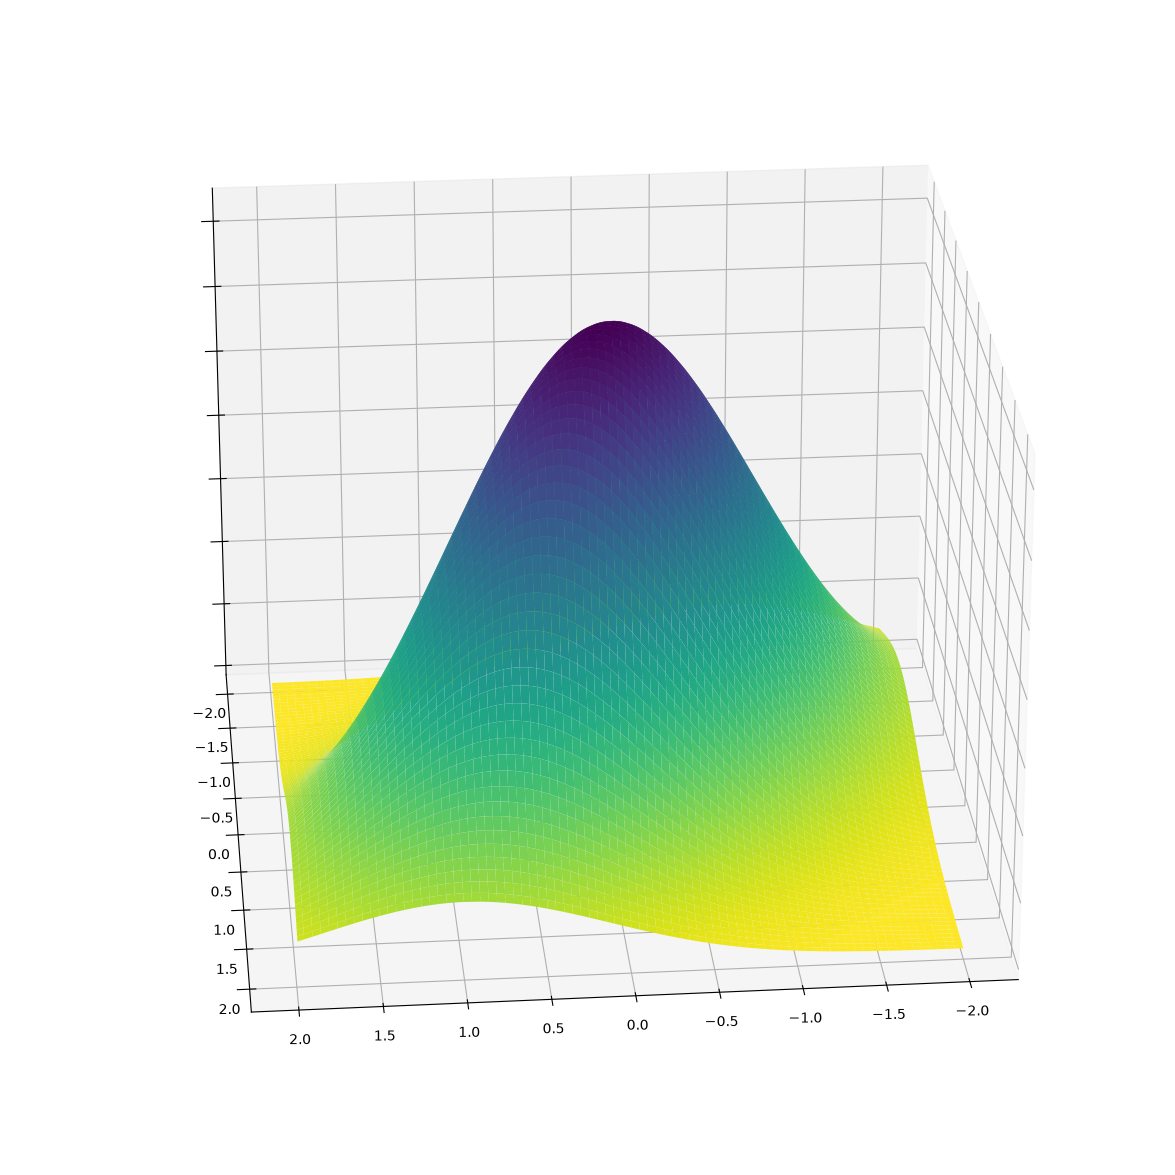

In [9]:
fig=plt.figure(figsize=(15,15))
plot3dangles(25, 85, fig, 111)
plt.show()

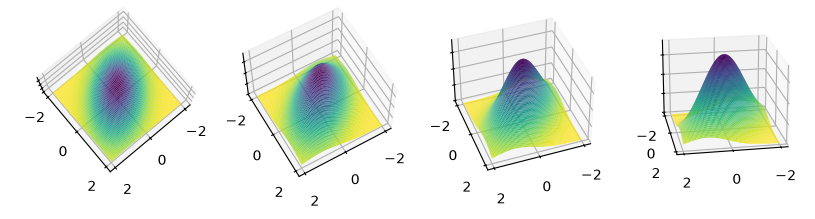

In [10]:
fig=plt.figure(figsize=(10,10))
plot3dangles(80, 50, fig, 141)
plot3dangles(60, 60, fig, 142)
plot3dangles(40, 70, fig, 143)
plot3dangles(20, 80, fig, 144)
plt.show()

:::{admonition} Lemma
Die multivariate Normalverteilung mit Erwartungswert $\mu$ und Kovarianz $\Sigma$ ist die Verteilung maximaler Entropie unter allen Verteilungen mit diesem Erwartungswert und dieser Kovarianzmatrix und Träger ganz $\mathbb{R}^n$.
:::

:::{admonition} Lemma
Ein Zufallsvektor $X = (X_1,\dots,X_n)$ (d.h. eine multivariate Verteilung) ist multivariat normalverteilt genau dann wenn jede mögliche Linearkombination $\sum_{i=1} \lambda_i X_i$ univariat normalverteilt ist.
:::

**Achtung**

Das heisst nicht, dass alle Linearkombinationen von normalverteilten Zufallsvariablen wieder normalverteilt sind! Ein Beispiel fast wie aus dem Datasaurus, wo $X$ und $Y$ einzeln normalverteilt sind, aber eine Abhängigkeit voneinander haben - und zack, $X+Y$ ist nicht normalverteilt (denn X+Y=0 hat eine Wahrscheinlichkeit von 50%):

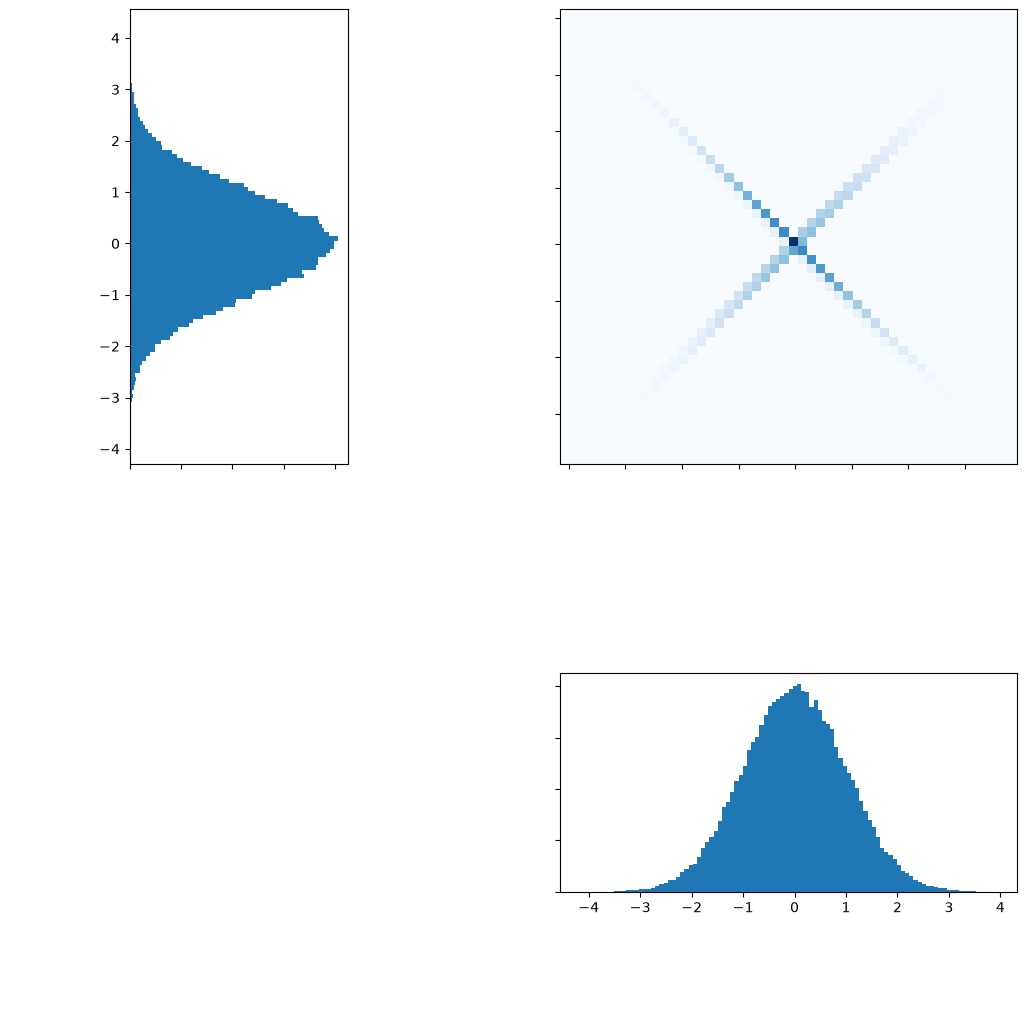

In [11]:
# plot the weirdo sample:
def plotalot2(x, y):
    fig, axs = plt.subplots(2,2, figsize=(13,13))
    axs[0,1].hist2d(x, y, bins=50, cmap=plt.cm.Blues)
    axs[0,1].set_xticklabels([])
    axs[0,1].set_yticklabels([])
    axs[1,1].hist(x, bins=100, density=True)
    axs[1,1].set_yticklabels([])
    axs[1,1].set_aspect(10)
    axs[0,0].hist(y, bins=100, density=True,
                  orientation="horizontal")
    axs[0,0].set_xticklabels([])
    axs[0,0].set_aspect(0.1)
    axs[1,0].set_axis_off()
    plt.show()

samplesize = 100000
x = st.norm.rvs(0, 1, size=samplesize)
t = 2*st.bernoulli.rvs(0.5, size=samplesize) - 1
y = t*x
plotalot2(x, y)

[Die Wikipedia hat einen schönen Artikel dazu, dass normalverteilte unkorrelierte Zufallsvariablen durchaus abhängig voneinander sein können.](https://en.wikipedia.org/wiki/Normally_distributed_and_uncorrelated_does_not_imply_independent)

Die Zufallsvariablen X, Y aus dem vorigen Plot sind genau so ein Beispiel, denn der Korrelationskoeffizient ist $0$.

Umgekehrt gibt es eine Aussage mit starken Voraussetzungen:

:::{admonition} Lemma
Sind $X$ und $Y$ zwei reelle Zufallsvariable, die gemeinsam bivariat normalverteilt sind, d.h. $(X,Y) \sim \mathcal{N}(\mu,\Sigma)$, dann folgt aus der Unkorreliertheit von $X$ und $Y$ bereits die Unabhängigkeit.

Es gilt auch die Umkehrung: wenn $X$ und $Y$ einzeln univariat normalverteilt sind, *und* unabhängig, dann ist $(X,Y)$ bivariat normalverteilt.
:::

**Aufgabe**:

Machen Sie sich klar, wie die Kovarianzmatrix im Fall der Unabhängigkeit aussieht.